In [ ]:
# ING200: Optimizacion - Proyecto
#**Integrantes:** María Fernanda González, Felipe Vicencio, Antonia Herrera, Matias Leiva, Esteban Escobar
#**Seccion:** 2 | **Profesor:** Jorge Acuña
#**Semestre:** Segundo semestre 2026

In [ ]:
# Integrantes: María Fernanda González, Felipe Vicencio, Antonia Herrera, Matias Leiva, Esteban Escobar
# Seccion: 2 | Profesor: Jorge Acuña | ING200: Optimizacion
!pip install gurobipy -q
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import defaultdict
env = gp.Env(params={"WLSACCESSID": "99ed8575-f5d8-48d7-8a4a-f13a718c047a",
               "WLSSECRET":   "96f7f9a0-93d8-424b-b1fd-490c18360f70",
               "LICENSEID":    2833630})

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2833630
Academic license 2833630 - for non-commercial use only - registered to an___@alumnos.uai.cl


In [ ]:
# =============================================================
# DATOS: copiados de datos_festival.py entregado con el enunciado
# Montos en millones de pesos (MM$)
# =============================================================
# =============================================================================
# DATOS DEL PROYECTO 2026-2: FIESTA DE VERANO DE VILLA PEUMAYÉN (copiados de datos_festival.py)
# Montos en millones de pesos (MM$).
# =============================================================================
NOCHES = ['Viernes', 'Sábado', 'Domingo']
FACTOR_NOCHE = {'Viernes': 0.90, 'Sábado': 1.00, 'Domingo': 0.85}

RECINTOS = {
    'Plaza de Armas':     {'capacidad': 12000, 'costo': 30},
    'Medialuna':          {'capacidad': 7500,  'costo': 18},
    'Gimnasio Municipal': {'capacidad': 4200,  'costo': 8},
}

ARTISTAS = {
    'La Sonora Copihue':           {'genero': 'Cumbia',  'nivel': 'G', 'popularidad': 1.08, 'costo': 52, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Los Volcanes':                {'genero': 'Rock',    'nivel': 'G', 'popularidad': 0.97, 'costo': 40, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Camila Arrebol':              {'genero': 'Pop',     'nivel': 'G', 'popularidad': 1.03, 'costo': 48, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Kevo Flow':                   {'genero': 'Urbano',  'nivel': 'G', 'popularidad': 1.12, 'costo': 58, 'noches': ['Viernes', 'Sábado']},
    'Los Cumbiancheros del Ñuble': {'genero': 'Cumbia',  'nivel': 'M', 'popularidad': 0.94, 'costo': 18, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Grupo Tierra Sur':            {'genero': 'Folclor', 'nivel': 'M', 'popularidad': 1.06, 'costo': 15, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'La Nena Real':                {'genero': 'Urbano',  'nivel': 'M', 'popularidad': 1.01, 'costo': 22, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Hermanas Quintral':       {'genero': 'Pop',     'nivel': 'M', 'popularidad': 0.92, 'costo': 17, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Ruta Cinco':                  {'genero': 'Rock',    'nivel': 'M', 'popularidad': 1.04, 'costo': 16, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Banda Fogata':                {'genero': 'Cumbia',  'nivel': 'P', 'popularidad': 1.11, 'costo': 7,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Conjunto Raíces del Valle':   {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.98, 'costo': 5,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Cantoras de Peumayén':    {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.89, 'costo': 4,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Niebla Austral':              {'genero': 'Rock',    'nivel': 'P', 'popularidad': 0.95, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Tomás del Lago':              {'genero': 'Pop',     'nivel': 'P', 'popularidad': 1.09, 'costo': 8,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Yisus Beat':                  {'genero': 'Urbano',  'nivel': 'P', 'popularidad': 0.91, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
}

TELONEROS = [('La Sonora Copihue', 'Banda Fogata')]
EXCLUSIONES = [('La Nena Real', 'Yisus Beat')]

PRESUPUESTO = 250
UMBRAL_SEGURIDAD = 20000
COSTO_SEGURIDAD = 25

BASE_NIVEL = {'G': 4200, 'M': 1900, 'P': 750}
FACTOR_GENERO = {'Cumbia': 1.20, 'Urbano': 1.10, 'Pop': 1.00, 'Rock': 0.95, 'Folclor': 0.65}
ARRASTRE = 0.20
MISMO_GENERO = -0.15
DOS_GRANDES = -0.10
AFINIDAD = {('Cumbia', 'Urbano'): 0.06, ('Pop', 'Rock'): 0.05, ('Pop', 'Urbano'): 0.03}


def demanda(artistas):
    """Demanda esperada (personas) de un conjunto de artistas que se presentan la misma noche.

    No considera la noche ni el recinto: el público esperado de la noche n en el recinto r es
        min(FACTOR_NOCHE[n] * demanda(artistas), capacidad del recinto r),
    redondeado al entero más cercano.
    También acepta conjuntos de uno o dos artistas (útil para analizar cancelaciones).
    """
    artistas = list(artistas)
    hay_grande = any(ARTISTAS[a]['nivel'] == 'G' for a in artistas)
    base = 0.0
    for a in artistas:
        datos = ARTISTAS[a]
        b = BASE_NIVEL[datos['nivel']] * FACTOR_GENERO[datos['genero']] * datos['popularidad']
        if hay_grande and datos['nivel'] != 'G':
            b *= 1 + ARRASTRE
        base += b
    interaccion = 0.0
    for i in range(len(artistas)):
        for j in range(i + 1, len(artistas)):
            a1, a2 = ARTISTAS[artistas[i]], ARTISTAS[artistas[j]]
            if a1['genero'] == a2['genero']:
                interaccion += MISMO_GENERO
            interaccion += AFINIDAD.get((a1['genero'], a2['genero']), AFINIDAD.get((a2['genero'], a1['genero']), 0))
            if a1['nivel'] == 'G' and a2['nivel'] == 'G':
                interaccion += DOS_GRANDES
    return base * (1 + interaccion)


def mostrar_parrilla(parrilla, titulo='Parrilla del festival'):
    """Muestra una parrilla con su público y su costo por noche.

    parrilla: lista de tuplas (noche, recinto, [artista1, artista2, artista3]).
    El costo mostrado incluye artistas y recinto, pero no el plan de seguridad.
    """
    import matplotlib.pyplot as plt
    orden = {n: i for i, n in enumerate(NOCHES)}
    parrilla = sorted(parrilla, key=lambda t: orden[t[0]])
    print(f'{titulo}\n' + '-' * 100)
    total_pub, total_costo, publicos = 0, 0, []
    for noche, recinto, artistas in parrilla:
        pub = round(min(FACTOR_NOCHE[noche] * demanda(artistas), RECINTOS[recinto]['capacidad']))
        costo = sum(ARTISTAS[a]['costo'] for a in artistas) + RECINTOS[recinto]['costo']
        total_pub += pub; total_costo += costo; publicos.append(pub)
        nombres = ', '.join(f"{a} ({ARTISTAS[a]['nivel']})" for a in artistas)
        print(f'{noche:8s} | {recinto:18s} | {pub:6,d} personas | {costo:4d} MM$ | {nombres}')
    print('-' * 100 + f'\nTotal: {total_pub:,} personas | {total_costo} MM$ (sin plan de seguridad)')
    plt.figure(figsize=(7, 3.5))
    barras = plt.bar([p[0] for p in parrilla], publicos, color=['#1565c0', '#c62828', '#2e7d32'][:len(parrilla)])
    for b, (noche, recinto, _) in zip(barras, parrilla):
        plt.text(b.get_x() + b.get_width() / 2, b.get_height(), recinto, ha='center', va='bottom', fontsize=9)
    plt.ylabel('Público esperado'); plt.title(titulo); plt.tight_layout(); plt.show()


LISTA_ARTISTAS = list(ARTISTAS)
print(f'Artistas candidatos : {len(LISTA_ARTISTAS)}')
print(f'Noches              : {NOCHES}')
print(f'Presupuesto base    : {PRESUPUESTO} MM$')
print(f'Umbral de seguridad : {UMBRAL_SEGURIDAD:,} personas (plan: {COSTO_SEGURIDAD} MM$)')
for r, v in RECINTOS.items():
    print(f'  {r:<20}: capacidad {v["capacidad"]:>6,} | arriendo {v["costo"]} MM$')
# Verificacion con el ejemplo del enunciado (debe dar 10.021,1)
print('Ejemplo enunciado   :', round(demanda(['La Sonora Copihue', 'Kevo Flow', 'Yisus Beat']), 1))

Artistas candidatos : 15
Noches              : ['Viernes', 'Sábado', 'Domingo']
Presupuesto base    : 250 MM$
Umbral de seguridad : 20,000 personas (plan: 25 MM$)
  Plaza de Armas      : capacidad 12,000 | arriendo 30 MM$
  Medialuna           : capacidad  7,500 | arriendo 18 MM$
  Gimnasio Municipal  : capacidad  4,200 | arriendo 8 MM$
Ejemplo enunciado   : 10021.1


In [ ]:
# =============================================================
# La demanda de una noche depende de la COMBINACION de artistas, por lo que
# se precalcula fuera del modelo para cada trio. El modelo solo elige una opcion por noche.
# =============================================================
def trio_valido(c):
    # Condicion 2: si esta el artista principal, su telonero debe ir en el mismo trio (misma noche)
    for (principal, telonero) in TELONEROS:
        if principal in c and telonero not in c:
            return False
    # Condicion 3 (misma noche): los artistas en disputa no comparten trio
    for (a1, a2) in EXCLUSIONES:
        if a1 in c and a2 in c:
            return False
    return True

TRIOS = [c for c in combinations(LISTA_ARTISTAS, 3) if trio_valido(c)]

def publico(artistas, n, r):
    # Publico esperado = round(min(factor noche * D(c), capacidad recinto)); sirve para 1, 2 o 3 artistas
    return round(min(FACTOR_NOCHE[n] * demanda(artistas), RECINTOS[r]['capacidad']))

RECINTOS_ORD = sorted(RECINTOS, key=lambda r: RECINTOS[r]['costo'])   # de mas barato a mas caro

OPC, P, COSTO = [], {}, {}
total_sin_poda = 0
for c in TRIOS:
    for n in NOCHES:
        if any(n not in ARTISTAS[a]['noches'] for a in c):        # Condicion 1: disponibilidad
            continue
        mejor_previo = -1
        for r in RECINTOS_ORD:
            total_sin_poda += 1
            p = publico(c, n, r)
            if p > mejor_previo:   # recinto mas caro solo se considera si aumenta el publico (no dominado)
                OPC.append((c, n, r))
                P[(c, n, r)] = p
                COSTO[(c, n, r)] = sum(ARTISTAS[a]['costo'] for a in c) + RECINTOS[r]['costo']
                mejor_previo = p

# Publico si cancela el peor artista de la opcion (se usa en la parte c)
W = {o: min(publico([b for b in o[0] if b != a], o[1], o[2]) for a in o[0]) for o in OPC}

M_SEG = 3 * max(v['capacidad'] for v in RECINTOS.values()) - UMBRAL_SEGURIDAD   # 36.000 - 20.000 = 16.000

print(f'Trios posibles      : {len(list(combinations(LISTA_ARTISTAS, 3)))}')
print(f'Trios validos       : {len(TRIOS)}')
print(f'Opciones (c,n,r)    : {total_sin_poda} sin poda -> {len(OPC)} variables x')
print(f'M plan de seguridad : {M_SEG:,}')

Trios posibles      : 455
Trios validos       : 365
Opciones (c,n,r)    : 3051 sin poda -> 1817 variables x
M plan de seguridad : 16,000


In [ ]:
def build_and_solve(budget=PRESUPUESTO, obj_type='max_pub', fix_pub=None, fix_peor=None,
                    extra=None, verbose=False):
    '''
    Construye y resuelve el modelo PLE de la Fiesta de Verano.

    Variables de decision:
      x[c,n,r] in {0,1} : 1 si la noche n se presenta el trio c en el recinto r
      s in {0,1}        : 1 si se implementa el plan de seguridad

    obj_type: 'max_pub'      -> maximizar publico total esperado
              'min_cost'     -> minimizar costo total (artistas + recintos + plan)
              'max_peor'     -> maximizar publico total si cancela el peor artista de cada noche
              'max_min_noche'-> maximizar el publico de la noche con menos publico
    extra: funcion extra(m, x, s) que agrega restricciones adicionales (partes c y d)
    '''
    m = gp.Model('festival', env=env)
    m.setParam('OutputFlag', 1 if verbose else 0)
    m.setParam('MIPGap', 0)                                   # optimalidad exacta

    # Variables
    x = m.addVars(OPC, vtype=GRB.BINARY, name='x')
    s = m.addVar(vtype=GRB.BINARY, name='s')

    pub_e  = gp.quicksum(P[o] * x[o] for o in OPC)
    cost_e = gp.quicksum(COSTO[o] * x[o] for o in OPC) + COSTO_SEGURIDAD * s
    peor_e = gp.quicksum(W[o] * x[o] for o in OPC)

    # (R1) Una parrilla (trio + recinto) por noche
    for n in NOCHES:
        m.addConstr(gp.quicksum(x[o] for o in OPC if o[1] == n) == 1, name=f'R1_{n}')
    # (R2) Cada artista se presenta a lo mas una vez
    for a in LISTA_ARTISTAS:
        m.addConstr(gp.quicksum(x[o] for o in OPC if a in o[0]) <= 1, name=f'R2_{a}')
    # (R3) Telonero: incorporada al construir TRIOS (trios con Sonora siempre incluyen a Fogata)
    # (R4) Disputa: a lo mas uno de los dos artistas en todo el festival
    for (a1, a2) in EXCLUSIONES:
        m.addConstr(gp.quicksum(x[o] for o in OPC if a1 in o[0] or a2 in o[0]) <= 1, name='R4')
    # (R5) Plan de seguridad si el publico supera el umbral
    m.addConstr(pub_e <= UMBRAL_SEGURIDAD + M_SEG * s, name='R5_seguridad')
    # (R6) Presupuesto
    m.addConstr(cost_e <= budget, name='R6_presupuesto')

    # Restricciones adicionales y de desempate
    if extra is not None:
        extra(m, x, s)
    if fix_pub is not None:
        m.addConstr(pub_e >= fix_pub, name='fix_pub')
    if fix_peor is not None:
        m.addConstr(peor_e >= fix_peor, name='fix_peor')

    # Funcion objetivo
    if obj_type == 'max_pub':
        m.setObjective(pub_e, GRB.MAXIMIZE)
    elif obj_type == 'min_cost':
        m.setObjective(cost_e, GRB.MINIMIZE)
    elif obj_type == 'max_peor':
        m.setObjective(peor_e, GRB.MAXIMIZE)
    elif obj_type == 'max_min_noche':
        z = m.addVar(name='z')
        for n in NOCHES:
            m.addConstr(gp.quicksum(P[o] * x[o] for o in OPC if o[1] == n) >= z)
        m.setObjective(z, GRB.MAXIMIZE)

    m.optimize()
    if m.status != GRB.OPTIMAL:
        return None

    elegidas = sorted([o for o in OPC if x[o].X > 0.5], key=lambda o: NOCHES.index(o[1]))
    return {
        'opciones':  elegidas,
        'parrilla':  [(n, r, list(c)) for (c, n, r) in elegidas],
        'publico':   round(pub_e.getValue()),
        'costo':     round(cost_e.getValue()),
        'seguridad': int(s.X > 0.5),
        'peor':      round(peor_e.getValue()),
        'por_noche': {o[1]: P[o] for o in elegidas},
        'peor_noche':{o[1]: W[o] for o in elegidas},
        'recinto':   {o[1]: o[2] for o in elegidas},
        'objetivo':  m.ObjVal,
    }


def resolver(budget=PRESUPUESTO, extra=None):
    # Resolucion secuencial: Etapa 1 max publico, Etapa 2 min costo con el publico fijo
    r1 = build_and_solve(budget, 'max_pub', extra=extra)
    if r1 is None:
        return None
    return build_and_solve(budget, 'min_cost', fix_pub=r1['publico'], extra=extra)


def report_results(res, label='', budget=PRESUPUESTO):
    sep = '=' * 65
    print(f'\n{sep}\n  RESULTADOS - {label}\n{sep}')
    print(f'\nPublico total esperado: {res["publico"]:,} personas')
    for n in NOCHES:
        print(f'  {n:<9}: {res["por_noche"][n]:>6,} personas | {res["recinto"][n]}')
    print(f'\nCosto total : {res["costo"]} MM$  ({res["costo"]/budget*100:.1f}% presupuesto de {budget} MM$)')
    print(f'Plan de seguridad: {"SI" if res["seguridad"] else "NO"}')
    elegidos = [a for (c, n, r) in res['opciones'] for a in c]
    print(f'\n{"Genero":<10} {"Contrat.":>9} {"Disp.":>6} {"Costo (MM$)":>12} {"% costo art.":>13}')
    print('-' * 55)
    costo_art = sum(ARTISTAS[a]['costo'] for a in elegidos)
    for g in FACTOR_GENERO:
        disp = [a for a in LISTA_ARTISTAS if ARTISTAS[a]['genero'] == g]
        cont = [a for a in elegidos if ARTISTAS[a]['genero'] == g]
        ct = sum(ARTISTAS[a]['costo'] for a in cont)
        print(f'{g:<10} {len(cont):>9} {len(disp):>6} {ct:>12} {ct/costo_art*100:>12.1f}%')
    print(f'\n{sep}\n  PARRILLA POR NOCHE\n{sep}')
    for (c, n, r) in res['opciones']:
        print(f'\n{n.upper()} - {r} (capacidad {RECINTOS[r]["capacidad"]:,}, arriendo {RECINTOS[r]["costo"]} MM$)')
        for a in c:
            d = ARTISTAS[a]
            print(f'    {a:<28} | {d["genero"]:<8} | nivel {d["nivel"]} | {d["costo"]:>3} MM$')
        print(f'    Demanda D(c) = {demanda(c):,.1f} | publico = {P[(c, n, r)]:,} | costo noche = {COSTO[(c, n, r)]} MM$')

Etapa 1 - Maximizar publico total esperado...
  -> Optimo: 19,999 personas
Etapa 2 - Minimizar costo total (publico = 19,999 fijo)...
  -> Costo minimo: 249 MM$

  RESULTADOS - SITUACION BASE - Parte (b)

Publico total esperado: 19,999 personas
  Viernes  :  9,657 personas | Plaza de Armas
  Sábado   :  7,045 personas | Medialuna
  Domingo  :  3,297 personas | Gimnasio Municipal

Costo total : 249 MM$  (99.6% presupuesto de 250 MM$)
Plan de seguridad: NO

Genero      Contrat.  Disp.  Costo (MM$)  % costo art.
-------------------------------------------------------
Cumbia             2      3           25         13.0%
Urbano             1      3           58         30.1%
Pop                3      3           73         37.8%
Rock               2      3           22         11.4%
Folclor            1      3           15          7.8%

  PARRILLA POR NOCHE

VIERNES - Plaza de Armas (capacidad 12,000, arriendo 30 MM$)
    Kevo Flow                    | Urbano   | nivel G |  58 MM$
    Lo

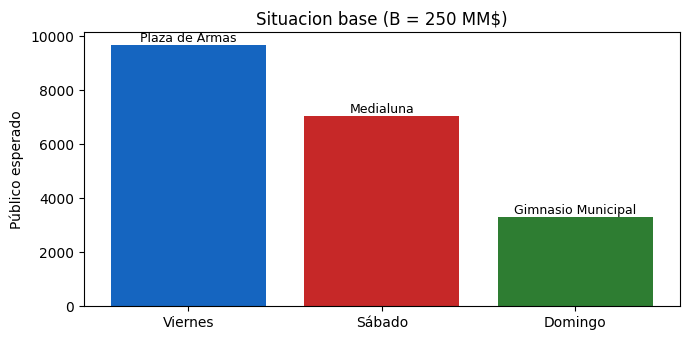

In [ ]:
print('Etapa 1 - Maximizar publico total esperado...')
r1 = build_and_solve(PRESUPUESTO, 'max_pub')
PUB_star = r1['publico']
print(f'  -> Optimo: {PUB_star:,} personas')

print(f'Etapa 2 - Minimizar costo total (publico = {PUB_star:,} fijo)...')
r_base = build_and_solve(PRESUPUESTO, 'min_cost', fix_pub=PUB_star)
print(f'  -> Costo minimo: {r_base["costo"]} MM$')

report_results(r_base, 'SITUACION BASE - Parte (b)')
mostrar_parrilla(r_base['parrilla'], 'Situacion base (B = 250 MM$)')

In [ ]:
# Interpretacion: mejor festival posible si se paga el plan de seguridad (s = 1)
r_plan = resolver(extra=lambda m, x, s: m.addConstr(s == 1))
print(f'Mejor solucion con plan de seguridad: {r_plan["publico"]:,} personas, costo {r_plan["costo"]} MM$')
print(f'Diferencia vs base: {r_plan["publico"] - r_base["publico"]:,} personas')

Mejor solucion con plan de seguridad: 18,853 personas, costo 250 MM$
Diferencia vs base: -1,146 personas


In [ ]:
sep = '=' * 65
print(f'{sep}\n  PUBLICO SI CANCELA CADA ARTISTA (mismo recinto)\n{sep}')
canc_rows = []
for (c, n, r) in r_base['opciones']:
    plan = P[(c, n, r)]
    print(f'\n{n.upper()} - {r} | publico planificado: {plan:,}')
    for a in c:
        resto = [b for b in c if b != a]
        q = publico(resto, n, r)
        print(f'    Cancela {a:<28} -> {q:>6,} personas ({q/plan*100:5.1f}% del planificado)')
        canc_rows.append({'noche': n, 'artista': a, 'plan': plan, 'cancela': q})
canc_df = pd.DataFrame(canc_rows)

  PUBLICO SI CANCELA CADA ARTISTA (mismo recinto)

VIERNES - Plaza de Armas | publico planificado: 9,657
    Cancela Kevo Flow                    ->  3,502 personas ( 36.3% del planificado)
    Cancela Los Cumbiancheros del Ñuble  ->  6,741 personas ( 69.8% del planificado)
    Cancela Las Hermanas Quintral        ->  7,390 personas ( 76.5% del planificado)

SÁBADO - Medialuna | publico planificado: 7,045
    Cancela Camila Arrebol               ->  1,986 personas ( 28.2% del planificado)
    Cancela Grupo Tierra Sur             ->  5,395 personas ( 76.6% del planificado)
    Cancela Niebla Austral               ->  5,897 personas ( 83.7% del planificado)

DOMINGO - Gimnasio Municipal | publico planificado: 3,297
    Cancela Ruta Cinco                   ->  1,544 personas ( 46.8% del planificado)
    Cancela Banda Fogata                 ->  2,405 personas ( 72.9% del planificado)
    Cancela Tomás del Lago               ->  2,445 personas ( 74.2% del planificado)


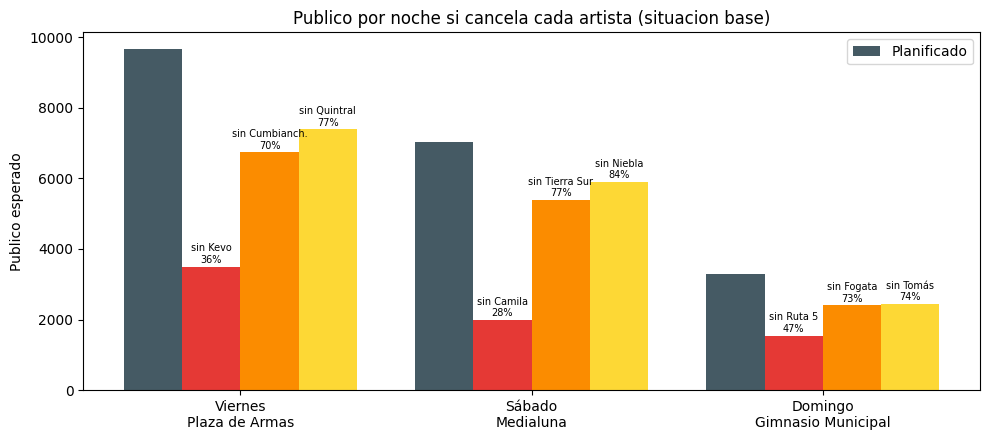

In [ ]:
CORTO = {'Kevo Flow': 'Kevo', 'Los Cumbiancheros del Ñuble': 'Cumbianch.', 'Las Hermanas Quintral': 'Quintral',
         'Camila Arrebol': 'Camila', 'Grupo Tierra Sur': 'Tierra Sur', 'Niebla Austral': 'Niebla',
         'Ruta Cinco': 'Ruta 5', 'Banda Fogata': 'Fogata', 'Tomás del Lago': 'Tomás'}
fig, ax = plt.subplots(figsize=(10, 4.5))
ancho = 0.2
for i, n in enumerate(NOCHES):
    d = canc_df[canc_df.noche == n]
    ax.bar(i - 1.5 * ancho, d['plan'].iloc[0], ancho, color='#455a64', label='Planificado' if i == 0 else None)
    for j, (_, f) in enumerate(d.iterrows()):
        ax.bar(i + (j - 0.5) * ancho, f['cancela'], ancho, color=['#e53935', '#fb8c00', '#fdd835'][j])
        ax.text(i + (j - 0.5) * ancho, f['cancela'] + 100,
                f"sin {CORTO.get(f['artista'], f['artista'])}\n{f['cancela']/f['plan']*100:.0f}%", ha='center', fontsize=7)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{n}\n{r_base['recinto'][n]}" for n in NOCHES])
ax.set_ylabel('Publico esperado'); ax.set_title('Publico por noche si cancela cada artista (situacion base)')
ax.legend(); plt.tight_layout()
plt.savefig('cancelaciones.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
# Alternativa A (alfa): en cada noche, si cancela cualquier artista se conserva al menos alfa del publico
def piso_relativo(alfa):
    def extra(m, x, s):
        for n in NOCHES:
            m.addConstr(gp.quicksum((W[o] - alfa * P[o]) * x[o] for o in OPC if o[1] == n) >= 0, name=f'A_{n}')
    return extra

# Alternativa B: al menos dos artistas grandes o medianos en cada noche
def respaldo_nivel(m, x, s):
    for o in OPC:
        if sum(ARTISTAS[a]['nivel'] in ('G', 'M') for a in o[0]) < 2:
            x[o].UB = 0

# Alternativa C (max-min): Etapa 1 max publico en el peor caso, Etapa 2 max publico, Etapa 3 min costo
def resolver_maxmin(budget=PRESUPUESTO):
    c1 = build_and_solve(budget, 'max_peor')
    c2 = build_and_solve(budget, 'max_pub', fix_peor=c1['peor'])
    return build_and_solve(budget, 'min_cost', fix_peor=c1['peor'], fix_pub=c2['publico'])

print(f'{"alfa":>6} {"Publico":>9} {"Costo":>7} {"Peor caso":>10}')
print('-' * 36)
curva = []
for alfa in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    ra = resolver(extra=piso_relativo(alfa))
    print(f'{alfa:>6.2f} {ra["publico"]:>9,} {ra["costo"]:>7} {ra["peor"]:>10,}')
    curva.append({'alfa': alfa, 'publico': ra['publico'], 'peor': ra['peor']})
curva_df = pd.DataFrame(curva)

alternativas = {'Base': r_base,
                'A (alfa = 0,40)': resolver(extra=piso_relativo(0.40)),
                'A (alfa = 0,45)': resolver(extra=piso_relativo(0.45)),
                'A (alfa = 0,50)': resolver(extra=piso_relativo(0.50)),
                'B (>= 2 G/M por noche)': resolver(extra=respaldo_nivel),
                'C (max-min)': resolver_maxmin()}

  alfa   Publico   Costo  Peor caso
------------------------------------
  0.30    19,998     244      8,398
  0.35    19,998     244      8,398
  0.40    19,998     247      9,034
  0.45    19,607     246     10,697
  0.50    19,265     250     10,666
  0.55    19,002     247     10,924
  0.60    17,979     244     11,084
  0.65    15,392     235     10,235



  COMPARACION DE ALTERNATIVAS - Parte (c.ii)
  Alternativa               Publico  Costo  Peor caso   Viernes                  Sábado                   Domingo               
  ------------------------------------------------------------------------------------------------
  Base                       19,999    249      7,032   Plaza     9,657 ( 36%)   Medialuna 7,045 ( 28%)   Gimnasio  3,297 ( 47%)
  A (alfa = 0,40)            19,998    247      9,034   Medialuna 7,500 ( 47%)   Plaza     9,841 ( 41%)   Gimnasio  2,657 ( 58%)
  A (alfa = 0,45)            19,607    246     10,697   Gimnasio  3,491 ( 47%)   Plaza     11,952 ( 58%)   Gimnasio  4,164 ( 52%)
  A (alfa = 0,50)            19,265    250     10,666   Gimnasio  3,980 ( 52%)   Plaza     11,952 ( 58%)   Gimnasio  3,333 ( 51%)
  B (>= 2 G/M por noche)     19,998    247      8,560   Medialuna 7,015 ( 38%)   Plaza     8,783 ( 38%)   Gimnasio  4,200 ( 62%)
  C (max-min)                13,886    250     12,139   Gimnasio  4,200 ( 82%) 

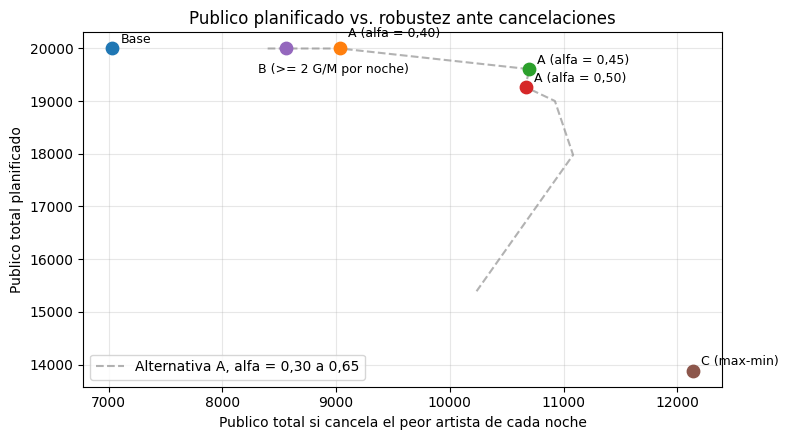

In [ ]:
sep = '=' * 100
print(f'\n{sep}\n  COMPARACION DE ALTERNATIVAS - Parte (c.ii)\n{sep}')
print(f'  {"Alternativa":<24} {"Publico":>8} {"Costo":>6} {"Peor caso":>10}   ' + '   '.join(f'{n:<22}' for n in NOCHES))
print(f'  {"-"*96}')
for k, v in alternativas.items():
    noches = '   '.join(f'{v["recinto"][n].split()[0]:<9} {v["por_noche"][n]:>5,} ({v["peor_noche"][n]/v["por_noche"][n]*100:>3.0f}%)'
                         for n in NOCHES)
    print(f'  {k:<24} {v["publico"]:>8,} {v["costo"]:>6} {v["peor"]:>10,}   {noches}')
print('  (entre parentesis: % del publico que se mantiene si cancela el peor artista de la noche)')

for k in ['A (alfa = 0,40)', 'A (alfa = 0,45)', 'B (>= 2 G/M por noche)', 'C (max-min)']:
    print(f'\n{k}:')
    for (c, n, r) in alternativas[k]['opciones']:
        print(f'    {n:<8} | {r:<18} | {P[(c, n, r)]:>6,} | {", ".join(c)}')

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, v in alternativas.items():
    ax.scatter(v['peor'], v['publico'], s=80, zorder=3)
    desp = {'B (>= 2 G/M por noche)': (-20, -18), 'A (alfa = 0,40)': (6, 8)}.get(k, (6, 4))
    ax.annotate(k, (v['peor'], v['publico']), textcoords='offset points', xytext=desp, fontsize=9)
ax.plot(curva_df['peor'], curva_df['publico'], '--', color='gray', alpha=0.6, label='Alternativa A, alfa = 0,30 a 0,65')
ax.set_xlabel('Publico total si cancela el peor artista de cada noche'); ax.set_ylabel('Publico total planificado')
ax.set_title('Publico planificado vs. robustez ante cancelaciones'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('robustez.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
rb, ra = alternativas['Base'], alternativas['A (alfa = 0,40)']
print('Recomendacion: Alternativa A con alfa = 0,40')
print(f'  Publico     : {rb["publico"]:,} -> {ra["publico"]:,} ({ra["publico"]-rb["publico"]:+,} personas)')
print(f'  Costo       : {rb["costo"]} -> {ra["costo"]} MM$ ({ra["costo"]-rb["costo"]:+} MM$)')
print(f'  Peor caso   : {rb["peor"]:,} -> {ra["peor"]:,} ({(ra["peor"]/rb["peor"]-1)*100:+.0f}%)')
print(f'  Peor noche  : {min(rb["peor_noche"][n]/rb["por_noche"][n] for n in NOCHES)*100:.0f}% -> '
      f'{min(ra["peor_noche"][n]/ra["por_noche"][n] for n in NOCHES)*100:.0f}% del publico planificado')

Recomendacion: Alternativa A con alfa = 0,40
  Publico     : 19,999 -> 19,998 (-1 personas)
  Costo       : 249 -> 247 MM$ (-2 MM$)
  Peor caso   : 7,032 -> 9,034 (+28%)
  Peor noche  : 28% -> 41% del publico planificado


In [ ]:
PRESUPUESTOS = [180, 220, 260, 300, 340]
res_B = {}
print(f'{"Presupuesto":>12} {"Publico":>8} {"Costo":>6} {"Plan":>5}   ' + '   '.join(f'{n:<26}' for n in NOCHES))
print('-' * 120)
for B in PRESUPUESTOS:
    rB = resolver(B)
    res_B[B] = rB
    noches = '   '.join(f'{rB["recinto"][n]:<18} {rB["por_noche"][n]:>6,}' for n in NOCHES)
    print(f'{B:>8} MM$ {rB["publico"]:>8,} {rB["costo"]:>6} {"SI" if rB["seguridad"] else "NO":>5}   {noches}')
for B in PRESUPUESTOS:
    print(f'\nPresupuesto {B} MM$:')
    for (c, n, r) in res_B[B]['opciones']:
        print(f'    {n:<8} | {r:<18} | {P[(c, n, r)]:>6,} | {", ".join(c)}')

 Presupuesto  Publico  Costo  Plan   Viernes                      Sábado                       Domingo                   
------------------------------------------------------------------------------------------------------------------------
     180 MM$   15,384    180    NO   Gimnasio Municipal  3,853   Medialuna           7,454   Gimnasio Municipal  4,077
     220 MM$   18,632    220    NO   Medialuna           7,005   Medialuna           7,500   Gimnasio Municipal  4,127
     260 MM$   20,000    252    NO   Medialuna           7,153   Plaza de Armas      9,514   Gimnasio Municipal  3,333
     300 MM$   22,350    297    SI   Medialuna           7,350   Medialuna           7,500   Medialuna           7,500
     340 MM$   25,255    332    SI   Medialuna           7,252   Plaza de Armas     10,730   Medialuna           7,273

Presupuesto 180 MM$:
    Viernes  | Gimnasio Municipal |  3,853 | La Nena Real, Banda Fogata, Tomás del Lago
    Sábado   | Medialuna          |  7,454 | Camila 

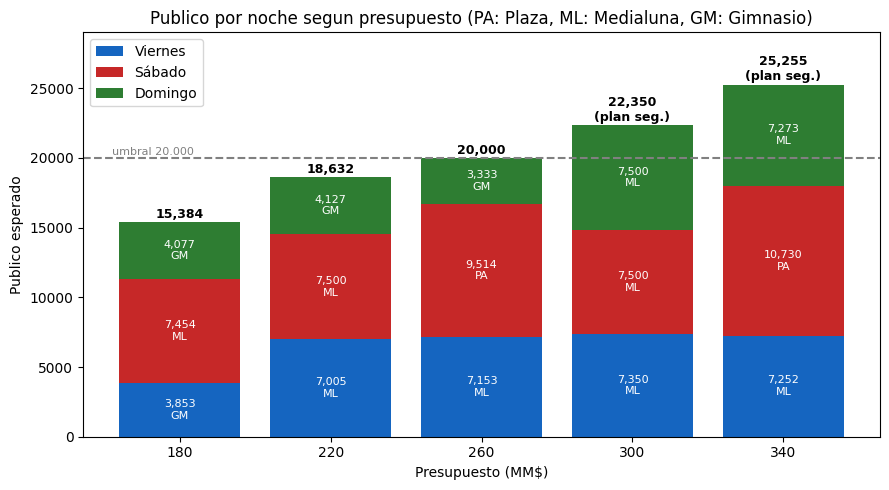

In [ ]:
colores = {'Viernes': '#1565c0', 'Sábado': '#c62828', 'Domingo': '#2e7d32'}
abrev = {'Plaza de Armas': 'PA', 'Medialuna': 'ML', 'Gimnasio Municipal': 'GM'}
fig, ax = plt.subplots(figsize=(9, 5))
xs = [str(B) for B in PRESUPUESTOS]
abajo = [0] * len(PRESUPUESTOS)
for n in NOCHES:
    vals = [res_B[B]['por_noche'][n] for B in PRESUPUESTOS]
    ax.bar(xs, vals, bottom=abajo, color=colores[n], label=n)
    for i, B in enumerate(PRESUPUESTOS):
        ax.text(i, abajo[i] + vals[i] / 2, f"{vals[i]:,}\n{abrev[res_B[B]['recinto'][n]]}", ha='center', va='center', color='white', fontsize=8)
    abajo = [a + v for a, v in zip(abajo, vals)]
for i, B in enumerate(PRESUPUESTOS):
    ax.text(i, abajo[i] + 300, f"{res_B[B]['publico']:,}" + ('\n(plan seg.)' if res_B[B]['seguridad'] else ''), ha='center', fontsize=9, fontweight='bold')
ax.axhline(UMBRAL_SEGURIDAD, ls='--', color='gray'); ax.text(-0.45, UMBRAL_SEGURIDAD + 200, 'umbral 20.000', color='gray', fontsize=8)
ax.set_xlabel('Presupuesto (MM$)'); ax.set_ylabel('Publico esperado'); ax.set_ylim(0, 29000)
ax.set_title('Publico por noche segun presupuesto (PA: Plaza, ML: Medialuna, GM: Gimnasio)')
ax.legend(loc='upper left'); plt.tight_layout()
plt.savefig('sensibilidad_presupuesto.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
print(f'{"Presupuesto":>12} ' + ' '.join(f'{n:>10}' for n in NOCHES) + '   Noche con menos publico')
print('-' * 70)
for B in PRESUPUESTOS + [250]:
    rB = res_B.get(B, r_base)
    peor = min(NOCHES, key=lambda n: rB['por_noche'][n])
    print(f'{B:>8} MM$ ' + ' '.join(f'{rB["por_noche"][n]:>10,}' for n in NOCHES) + f'   {peor} ({rB["recinto"][peor]})')
print('\nFactores de asistencia:', FACTOR_NOCHE)
print('Kevo Flow disponible:', ARTISTAS['Kevo Flow']['noches'])

 Presupuesto    Viernes     Sábado    Domingo   Noche con menos publico
----------------------------------------------------------------------
     180 MM$      3,853      7,454      4,077   Viernes (Gimnasio Municipal)
     220 MM$      7,005      7,500      4,127   Domingo (Gimnasio Municipal)
     260 MM$      7,153      9,514      3,333   Domingo (Gimnasio Municipal)
     300 MM$      7,350      7,500      7,500   Viernes (Medialuna)
     340 MM$      7,252     10,730      7,273   Viernes (Medialuna)
     250 MM$      9,657      7,045      3,297   Domingo (Gimnasio Municipal)

Factores de asistencia: {'Viernes': 0.9, 'Sábado': 1.0, 'Domingo': 0.85}
Kevo Flow disponible: ['Viernes', 'Sábado']


  COMPARACION DE PROPUESTAS - Parte (d.iii)
  Alternativa                     Publico  Costo   Viernes                    Sábado                     Domingo                 
  ----------------------------------------------------------------------------------------------------------
  Base                             19,999    249   Plaza de Armas     9,657   Medialuna          7,045   Gimnasio Municipal 3,297
  Minimo solo domingo (5.000)      19,998    244   Gimnasio Municipal 1,899   Plaza de Armas    10,599   Medialuna          7,500
  P1: minimo todas (L = 5.000)     19,994    250   Medialuna          6,759   Medialuna          7,317   Medialuna          5,918
  P1: minimo todas (L = 6.000)     19,987    250   Medialuna          6,314   Medialuna          7,454   Medialuna          6,219
  P2: un grande cada noche         19,994    250   Medialuna          6,759   Medialuna          7,317   Medialuna          5,918
  P3: equilibrio beta = 0,9        19,936    250   Medialuna       

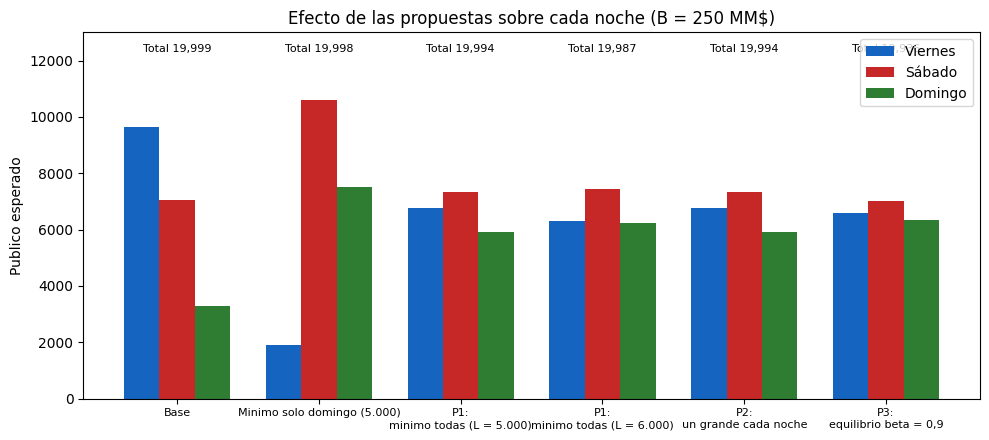

In [ ]:
# P1: publico minimo L en TODAS las noches
def minimo_por_noche(L, noches=NOCHES):
    def extra(m, x, s):
        for n in noches:
            m.addConstr(gp.quicksum(P[o] * x[o] for o in OPC if o[1] == n) >= L, name=f'min_{n}')
    return extra

# P2: un artista grande cada noche
def grande_cada_noche(m, x, s):
    for n in NOCHES:
        m.addConstr(gp.quicksum(x[o] for o in OPC if o[1] == n and any(ARTISTAS[a]['nivel'] == 'G' for a in o[0])) == 1)

# P3: equilibrio, cada noche con al menos beta veces el publico de cualquier otra
def equilibrio(beta):
    def extra(m, x, s):
        for n in NOCHES:
            for k in NOCHES:
                if n != k:
                    m.addConstr(gp.quicksum(P[o] * x[o] for o in OPC if o[1] == n)
                                >= beta * gp.quicksum(P[o] * x[o] for o in OPC if o[1] == k))
    return extra

prop_d = {'Base': r_base,
          'Minimo solo domingo (5.000)': resolver(extra=minimo_por_noche(5000, ['Domingo'])),
          'P1: minimo todas (L = 5.000)': resolver(extra=minimo_por_noche(5000)),
          'P1: minimo todas (L = 6.000)': resolver(extra=minimo_por_noche(6000)),
          'P2: un grande cada noche': resolver(extra=grande_cada_noche),
          'P3: equilibrio beta = 0,9': resolver(extra=equilibrio(0.9))}

sep = '=' * 110
print(f'{sep}\n  COMPARACION DE PROPUESTAS - Parte (d.iii)\n{sep}')
print(f'  {"Alternativa":<30} {"Publico":>8} {"Costo":>6}   ' + '   '.join(f'{n:<24}' for n in NOCHES))
print(f'  {"-"*106}')
for k, v in prop_d.items():
    print(f'  {k:<30} {v["publico"]:>8,} {v["costo"]:>6}   ' +
          '   '.join(f'{v["recinto"][n]:<18}{v["por_noche"][n]:>6,}' for n in NOCHES))
for k in list(prop_d)[1:]:
    print(f'\n{k}:')
    for (c, n, r) in prop_d[k]['opciones']:
        print(f'    {n:<8} | {r:<18} | {P[(c, n, r)]:>6,} | {", ".join(c)}')

fig, ax = plt.subplots(figsize=(10, 4.5))
nombres = list(prop_d); ancho = 0.25
for j, n in enumerate(NOCHES):
    ax.bar([i + (j - 1) * ancho for i in range(len(nombres))], [prop_d[k]['por_noche'][n] for k in nombres], ancho, color=colores[n], label=n)
for i, k in enumerate(nombres):
    ax.text(i, 12300, f"Total {prop_d[k]['publico']:,}", ha='center', fontsize=8)
ax.set_xticks(range(len(nombres))); ax.set_xticklabels([k.replace(': ', ':\n') for k in nombres], fontsize=8)
ax.set_ylabel('Publico esperado'); ax.set_ylim(0, 13000); ax.set_title('Efecto de las propuestas sobre cada noche (B = 250 MM$)')
ax.legend(); plt.tight_layout(); plt.savefig('propuestas_d.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
def presupuesto_requerido(L, publico_objetivo):
    # Minimo costo para cumplir L en todas las noches sin perder publico (presupuesto libre)
    rq = build_and_solve(10**6, 'min_cost', fix_pub=publico_objetivo, extra=minimo_por_noche(L))
    return rq['costo'] if rq else None

L_MAX = round(build_and_solve(PRESUPUESTO, 'max_min_noche')['objetivo'])
print(f'Maximo publico minimo por noche alcanzable con 250 MM$: {L_MAX:,}\n')

NIVELES = [3297, 4000, 4500, 5000, 5500, 6000, 6300, 6400, L_MAX, 7000, 7500]
print(f'{"L":>6} {"Publico (B=250)":>16} {"Perdida":>8} {"Domingo":>8} {"Presup. requerido":>18} {"Adicional":>10}')
print('-' * 72)
filas = []
for L in NIVELES:
    rL = resolver(extra=minimo_por_noche(L))
    req = presupuesto_requerido(L, r_base['publico'])
    if rL:
        print(f'{L:>6,} {rL["publico"]:>16,} {r_base["publico"]-rL["publico"]:>8,} {rL["por_noche"]["Domingo"]:>8,} {req:>14} MM$ {req-PRESUPUESTO:>+9}')
    else:
        print(f'{L:>6,} {"infactible":>16} {"-":>8} {"-":>8} {req:>14} MM$ {req-PRESUPUESTO:>+9}')
    filas.append({'L': L, 'publico': rL['publico'] if rL else None,
                  'perdida': r_base['publico'] - rL['publico'] if rL else None, 'requerido': req})
L_df = pd.DataFrame(filas)

Maximo publico minimo por noche alcanzable con 250 MM$: 6,522

     L  Publico (B=250)  Perdida  Domingo  Presup. requerido  Adicional
------------------------------------------------------------------------
 3,297           19,999        0    3,297            249 MM$        -1
 4,000           19,998        1    4,200            253 MM$        +3
 4,500           19,994        5    5,918            254 MM$        +4
 5,000           19,994        5    5,918            254 MM$        +4
 5,500           19,994        5    5,918            254 MM$        +4
 6,000           19,987       12    6,219            254 MM$        +4
 6,300           19,967       32    6,336            254 MM$        +4
 6,400           19,774      225    6,625            254 MM$        +4
 6,522           19,774      225    6,625            277 MM$       +27
 7,000       infactible        -        -            289 MM$       +39
 7,500       infactible        -        -            303 MM$       +53


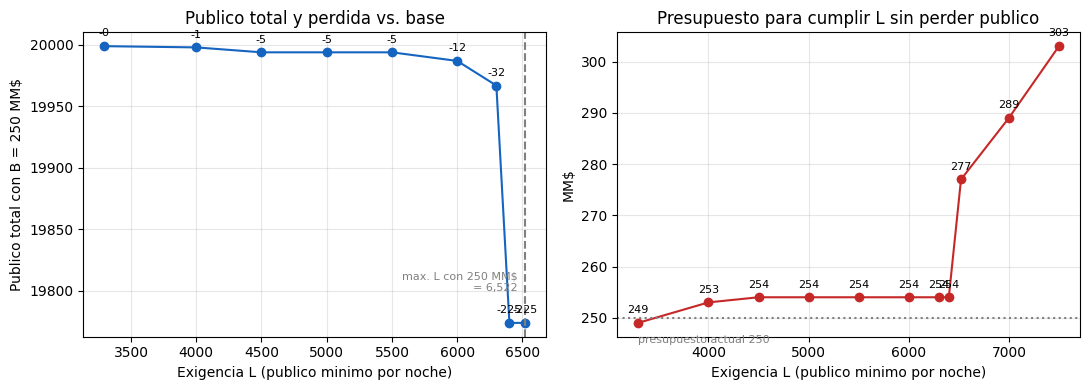

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
d = L_df.dropna(subset=['publico'])
ax1.plot(d['L'], d['publico'], 'o-', color='#1565c0')
for _, f in d.iterrows():
    ax1.annotate(f"-{int(f['perdida'])}", (f['L'], f['publico']), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax1.axvline(L_MAX, ls='--', color='gray'); ax1.text(L_MAX - 60, 19800, f'max. L con 250 MM$\n= {L_MAX:,}', fontsize=8, color='gray', ha='right')
ax1.set_xlabel('Exigencia L (publico minimo por noche)'); ax1.set_ylabel('Publico total con B = 250 MM$')
ax1.set_title('Publico total y perdida vs. base'); ax1.grid(alpha=0.3)
ax2.plot(L_df['L'], L_df['requerido'], 'o-', color='#c62828')
for _, f in L_df.iterrows():
    ax2.annotate(f"{int(f['requerido'])}", (f['L'], f['requerido']), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax2.axhline(PRESUPUESTO, ls=':', color='gray'); ax2.text(3300, PRESUPUESTO - 5, 'presupuesto actual 250', fontsize=8, color='gray')
ax2.set_xlabel('Exigencia L (publico minimo por noche)'); ax2.set_ylabel('MM$')
ax2.set_title('Presupuesto para cumplir L sin perder publico'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('sensibilidad_L.png', dpi=150, bbox_inches='tight'); plt.show()